## **1. Import Libraries**

In [94]:
import pandas as pd
import numpy as np
import re

## **2. Load Dataset**
> Di Colab, Google Drive dihubungkan dengan **drive.mount()**,



In [95]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Colab Notebooks/DATMIN/sleep_health_data_bersih_2.csv'

dataset = pd.read_csv(file_path)
print('Ukuran dataset: %d baris dan %d kolom\n' % dataset.shape)
print('Lima data teratas:')
print(dataset.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ukuran dataset: 200 baris dan 20 kolom

Lima data teratas:
   no  age  gender  sleep_duration_hrs  sleep_quality_score  exercise_day  \
0   1   29  Female                6.50                  6.6             0   
1   2   55  Female                8.32                  6.9             1   
2   3   42    Male                6.57                  1.0             1   
3   4   37    Male                6.79                  6.4             1   
4   5   23    Male                5.02                  3.2             0   

   steps_that_day  stress_score  heart_rate_resting_bpm  \
0            6592          4.40                      63   
1           10111          4.00                      52   
2            9222          7.80                      72   
3            9190          4.90                      71   
4            4273          5.55                      7

### Struktur dan Statistik Data
> **info()** menampilkan nama kolom, jumlah data, dan tipe data. **describe()**`menampilkan ringkasan statistik (rata-rata, minimum, maksimum, dll.) untuk kolom angka.**isna().sum()** memeriksa nilai kosong.



In [96]:
dataset.info()
print('\nJumlah nilai kosong:', dataset.isna().sum().sum())
print('Jumlah baris duplikat:', dataset.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   no                           200 non-null    int64  
 1   age                          200 non-null    int64  
 2   gender                       200 non-null    object 
 3   sleep_duration_hrs           200 non-null    float64
 4   sleep_quality_score          200 non-null    float64
 5   exercise_day                 200 non-null    int64  
 6   steps_that_day               200 non-null    int64  
 7   stress_score                 200 non-null    float64
 8   heart_rate_resting_bpm       200 non-null    int64  
 9   screen_time_before_bed_mins  200 non-null    int64  
 10  caffeine_mg_before_bed       200 non-null    int64  
 11  alcohol_units_before_bed     200 non-null    int64  
 12  nap_duration_mins            200 non-null    int64  
 13  kelompok_usia       

In [97]:
dataset.describe().round(2)

,no,age,sleep_duration_hrs,sleep_quality_score,exercise_day,steps_that_day,stress_score,heart_rate_resting_bpm,screen_time_before_bed_mins,caffeine_mg_before_bed,alcohol_units_before_bed,nap_duration_mins,total_tidur_sehari_hrs
count,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00
mean,100.50,33.99,6.52,5.01,0.45,7307.31,5.68,67.09,57.78,44.50,0.60,15.96,6.79
std,57.88,11.01,1.32,1.46,0.50,3382.57,1.53,7.14,38.65,79.29,1.07,22.93,1.36
min,1.00,18.00,3.00,1.00,0.00,500.00,1.60,45.00,5.00,0.00,0.00,0.00,3.00
25%,50.75,25.00,5.63,3.90,0.00,5046.25,4.70,62.00,27.75,0.00,0.00,0.00,5.95
50%,100.50,32.50,6.44,5.00,0.00,7424.00,5.70,67.00,48.50,0.00,0.00,0.00,6.66
75%,150.25,42.00,7.37,6.10,1.00,9255.50,6.70,72.00,79.00,80.00,1.00,31.00,7.69
max,200.00,62.00,10.50,7.90,1.00,16941.00,9.30,87.00,180.00,400.00,6.00,83.00,11.02


## **3. Agregasi Data**
Seperti **groupby + sum** pada PPT (GMV per bulan), di sini **groupby + mean **untuk rata-rata kualitas tidur per kelompok usia.

In [98]:
urutan = ['Remaja-dewasa awal (<=24)', 'Dewasa muda (25-34)', 'Dewasa (35-49)', 'Paruh baya (>=50)']
usia = dataset.groupby('kelompok_usia')['sleep_quality_score'].mean().loc[urutan].reset_index()
print(usia)

               kelompok_usia  sleep_quality_score
0  Remaja-dewasa awal (<=24)             5.039130
1        Dewasa muda (25-34)             5.163235
2             Dewasa (35-49)             4.922581
3          Paruh baya (>=50)             4.720833


# VISUALISASI 1 – Line Chart Tren Kualitas Tidur

### **4. Membuat Line Chart (versi dasar)**
> Tujuan: melihat pola kualitas tidur antar kelompok usia dengan jelas.







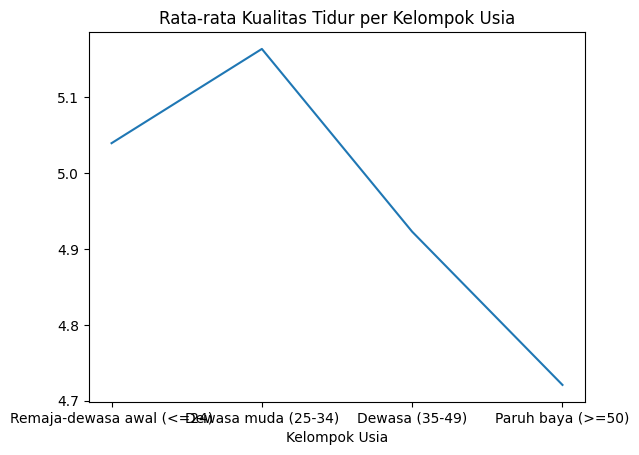

In [99]:
plt.plot(usia['kelompok_usia'], usia['sleep_quality_score'])
plt.title('Rata-rata Kualitas Tidur per Kelompok Usia')
plt.xlabel('Kelompok Usia')
plt.show()

### **5. Mengubah Figure Size**
> **plt.figure(figsize=(12,5))** membuat grafik lebih lebar. Judul diubah       **(fontsize, color, pad).**



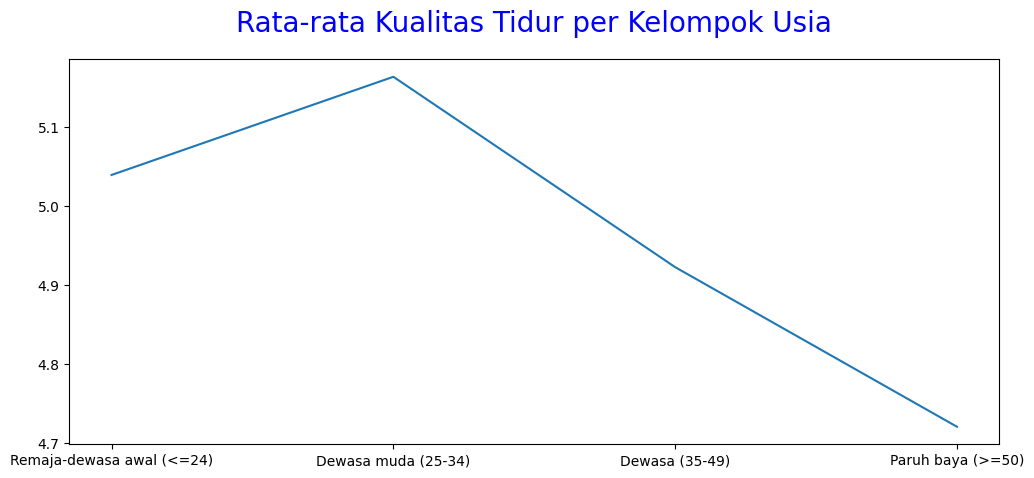

In [100]:
plt.figure(figsize=(12,5))
plt.plot(usia['kelompok_usia'], usia['sleep_quality_score'])
plt.title('Rata-rata Kualitas Tidur per Kelompok Usia', loc='center', pad=20, fontsize=20, color='blue')
plt.show()

### **6. Menambahkan Title dan Axis Labels**
> **plt.title, plt.xlabel, plt.ylabel** dipasang sebelum **plt.show().**






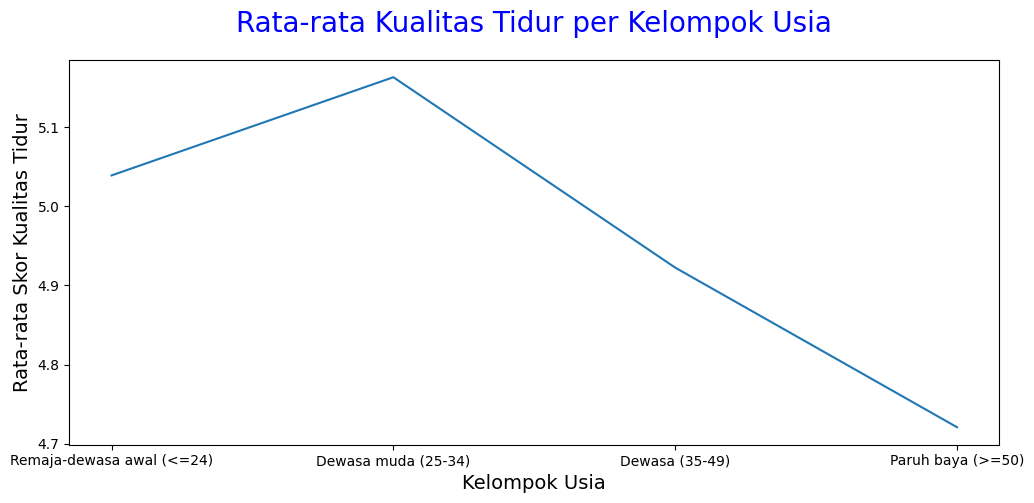

In [111]:
plt.figure(figsize=(12,5))
plt.plot(usia['kelompok_usia'], usia['sleep_quality_score'])
plt.title('Rata-rata Kualitas Tidur per Kelompok Usia', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Kelompok Usia', fontsize=14)
plt.ylabel('Rata-rata Skor Kualitas Tidur', fontsize=14)
plt.show()

### **7. Kustomisasi Line dan Point**
> color, marker, linestyle, linewidth mengubah warna, bentuk titik, jenis garis, dan ketebalan.



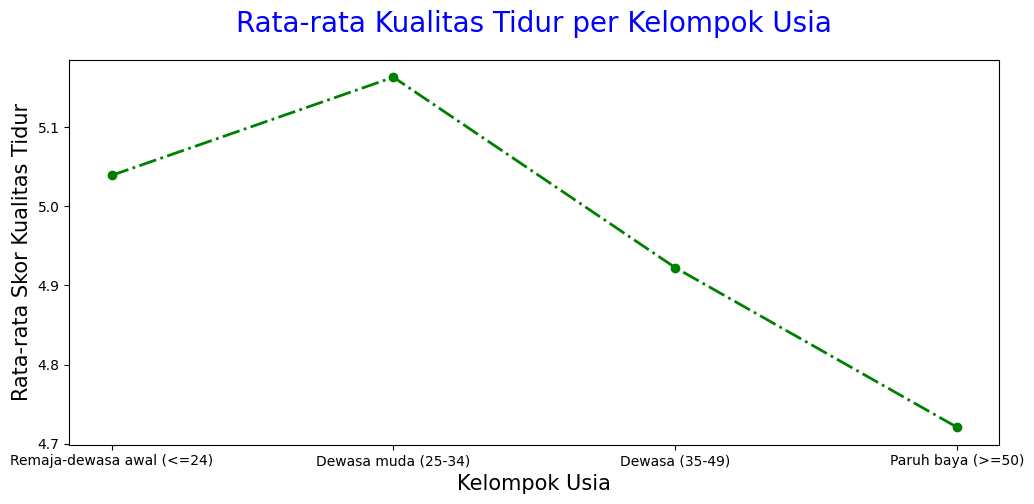

In [101]:
plt.figure(figsize=(12,5))
plt.plot(usia['kelompok_usia'], usia['sleep_quality_score'], color='green', marker='o', linestyle='-.', linewidth=2)
plt.title('Rata-rata Kualitas Tidur per Kelompok Usia', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Kelompok Usia', fontsize=15)
plt.ylabel('Rata-rata Skor Kualitas Tidur', fontsize=15)
plt.show()

### **8. Kustomisasi Grid**
>**plt.grid()** memudahkan memetakan titik ke sumbu y.



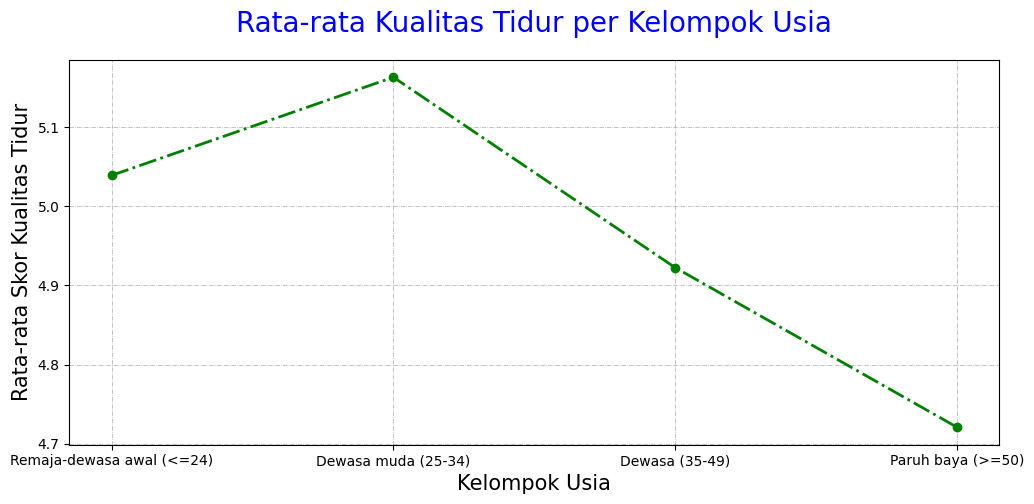

In [102]:
plt.figure(figsize=(12,5))
plt.plot(usia['kelompok_usia'], usia['sleep_quality_score'], color='green', marker='o', linestyle='-.', linewidth=2)
plt.title('Rata-rata Kualitas Tidur per Kelompok Usia', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Kelompok Usia', fontsize=15)
plt.ylabel('Rata-rata Skor Kualitas Tidur', fontsize=15)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)
plt.show()

### **9. Menambahkan Informasi pada Plot**
> **plt.ylim(ymin=0)** membuat sumbu y mulai dari 0, **plt.text()** menambah teks informasi di grafik.

---



---





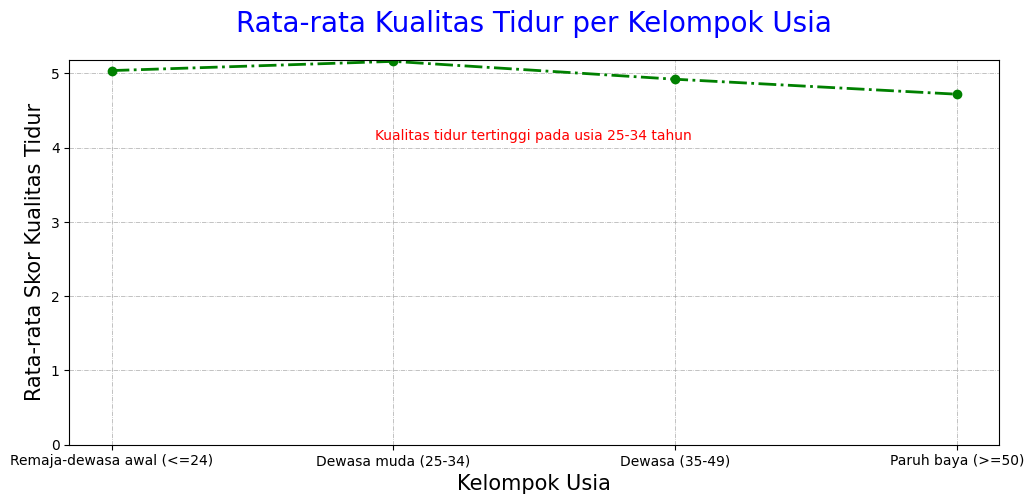

In [103]:
plt.figure(figsize=(12,5))
plt.plot(usia['kelompok_usia'], usia['sleep_quality_score'], color='green', marker='o', linestyle='-.', linewidth=2)
plt.title('Rata-rata Kualitas Tidur per Kelompok Usia', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Kelompok Usia', fontsize=15)
plt.ylabel('Rata-rata Skor Kualitas Tidur', fontsize=15)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)
plt.ylim(ymin=0)
plt.text(0.38, 0.72, 'Kualitas tidur tertinggi pada usia 25-34 tahun', transform=plt.gcf().transFigure, color='red')
plt.show()

**Interpretasi:** kualitas tidur tertinggi pada usia 25–34 tahun (±5,16), terendah pada usia ≥50 tahun (±4,72). Selisih antar kelompok kecil, sehingga usia bukan pembeda yang kuat.

# **VISUALISASI 2 Bar Chart Kategori Durasi Tidur**
> Bar chart membandingkan jumlah antar kategori. **value_counts()** menghitung jumlah responden per kategori.



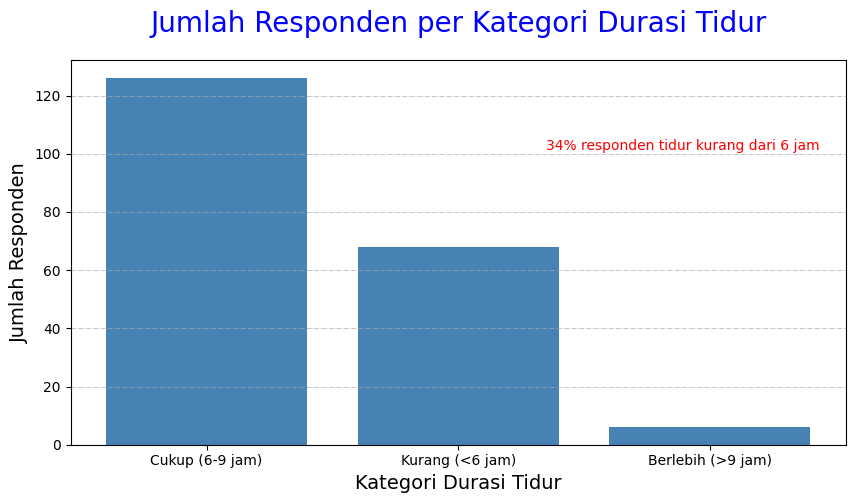

In [104]:
durasi = dataset['kategori_durasi_tidur'].value_counts()
plt.figure(figsize=(10,5))
plt.bar(durasi.index, durasi.values, color='steelblue')
plt.title('Jumlah Responden per Kategori Durasi Tidur', pad=20, fontsize=20, color='blue')
plt.xlabel('Kategori Durasi Tidur', fontsize=14)
plt.ylabel('Jumlah Responden', fontsize=14)
plt.grid(axis='y', color='darkgray', linestyle='-.', linewidth=0.5)
plt.text(0.6, 0.7, '34% responden tidur kurang dari 6 jam', transform=plt.gcf().transFigure, color='red')
plt.show()

# **VISUALISASI 3  Histogram Sebaran Durasi Tidur**
> Histogram menunjukkan bagaimana nilai durasi tidur tersebar.



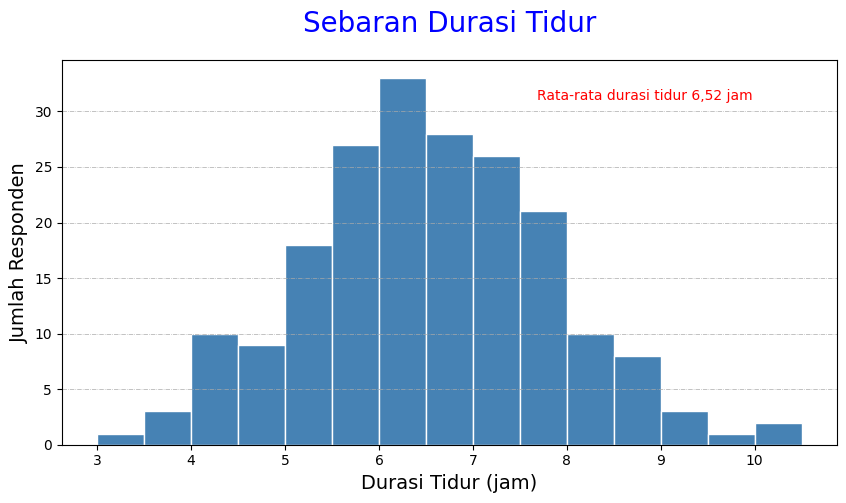

In [105]:
plt.figure(figsize=(10,5))
plt.hist(dataset['sleep_duration_hrs'], bins=15, color='steelblue', edgecolor='white')
plt.title('Sebaran Durasi Tidur', pad=20, fontsize=20, color='blue')
plt.xlabel('Durasi Tidur (jam)', fontsize=14)
plt.ylabel('Jumlah Responden', fontsize=14)
plt.grid(axis='y', color='darkgray', linestyle='-.', linewidth=0.5)
plt.text(0.6, 0.8, 'Rata-rata durasi tidur 6,52 jam', transform=plt.gcf().transFigure, color='red')
plt.show()

**Interpretasi:** sebaran berbentuk lonceng dengan puncak di sekitar 6 jam. Rata-rata durasi tidur 6,52 jam, di bawah anjuran 7 jam.

# **VISUALISASI 4 Bar Chart Rata-rata Kualitas Tidur per Rentang Durasi Tidur**
> Durasi tidur dikelompokkan ke dalam rentang jam dengan **pd.cut()**, lalu rata-rata skor kualitas tidur tiap rentang dihitung dengan **groupby + mean** dan ditampilkan dengan **plt.bar()**.



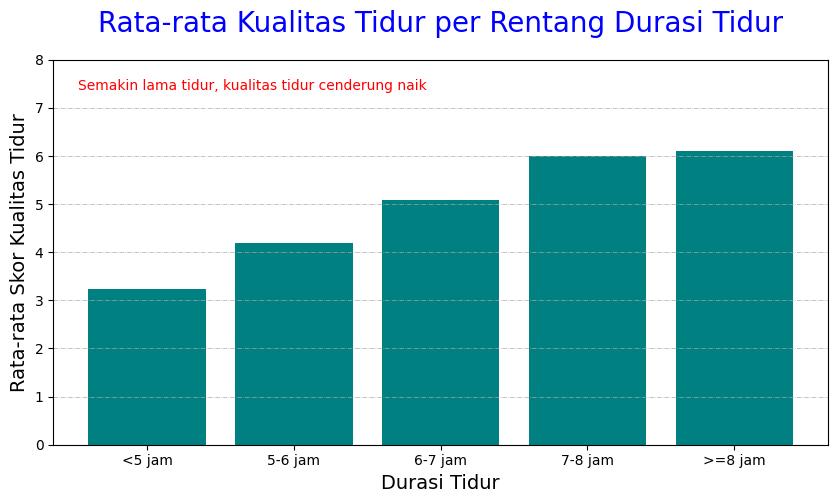

In [106]:
rentang_durasi = pd.cut(dataset['sleep_duration_hrs'], bins=[0, 5, 6, 7, 8, 12], labels=['<5 jam', '5-6 jam', '6-7 jam', '7-8 jam', '>=8 jam'], right=False)
rata_durasi = dataset.groupby(rentang_durasi, observed=False)['sleep_quality_score'].mean()

plt.figure(figsize=(10,5))
plt.bar(rata_durasi.index.astype(str), rata_durasi.values, color='teal')
plt.title('Rata-rata Kualitas Tidur per Rentang Durasi Tidur', pad=20, fontsize=20, color='blue')
plt.xlabel('Durasi Tidur', fontsize=14)
plt.ylabel('Rata-rata Skor Kualitas Tidur', fontsize=14)
plt.grid(axis='y', color='darkgray', linestyle='-.', linewidth=0.5)
plt.ylim(0, 8)
plt.text(0.15, 0.82, 'Semakin lama tidur, kualitas tidur cenderung naik', transform=plt.gcf().transFigure, color='red')
plt.show()

**Interpretasi:** batang makin tinggi ke kanan. Responden tidur kurang dari 5 jam punya rata-rata kualitas tidur sekitar 3,2, sedangkan yang tidur 7 jam atau lebih sekitar 6,0. Artinya durasi tidur berhubungan positif dengan kualitas tidur (korelasi ±0,62); setelah 7 jam kenaikannya mendatar.

# **VISUALISASI 5 Bar Chart Rata-rata Kualitas Tidur per Rentang Skor Stres**

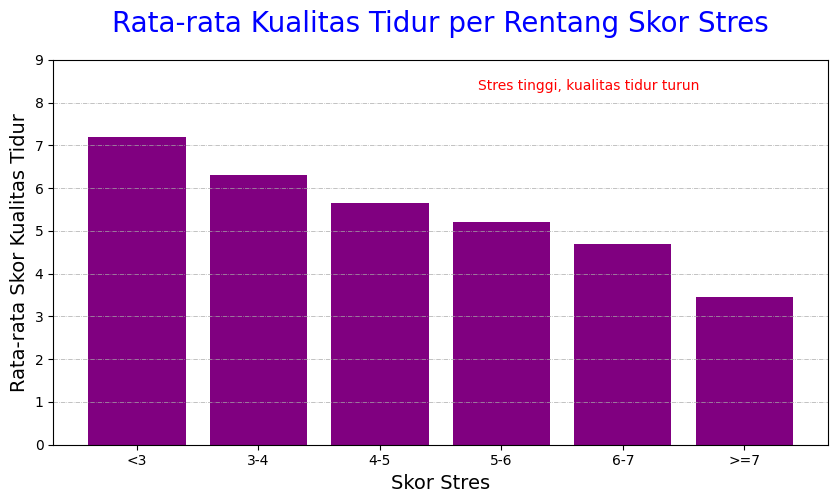

In [107]:
rentang_stres = pd.cut(dataset['stress_score'], bins=[0, 3, 4, 5, 6, 7, 11], labels=['<3', '3-4', '4-5', '5-6', '6-7', '>=7'], right=False)
rata_stres = dataset.groupby(rentang_stres, observed=False)['sleep_quality_score'].mean()

plt.figure(figsize=(10,5))
plt.bar(rata_stres.index.astype(str), rata_stres.values, color='purple')
plt.title('Rata-rata Kualitas Tidur per Rentang Skor Stres', pad=20, fontsize=20, color='blue')
plt.xlabel('Skor Stres', fontsize=14)
plt.ylabel('Rata-rata Skor Kualitas Tidur', fontsize=14)
plt.grid(axis='y', color='darkgray', linestyle='-.', linewidth=0.5)
plt.ylim(0, 9)
plt.text(0.55, 0.82, 'Stres tinggi, kualitas tidur turun', transform=plt.gcf().transFigure, color='red')
plt.show()

**Interpretasi:** batang makin pendek ke kanan. Responden dengan skor stres di bawah 3 punya rata-rata kualitas tidur sekitar 7,2, sedangkan skor stres 7 ke atas hanya sekitar 3,5. Artinya semakin tinggi stres, kualitas tidur semakin rendah (korelasi negatif ±−0,64).

# **VISUALISASI 6 Bar Chart Kualitas Tidur per Tingkat Stres**

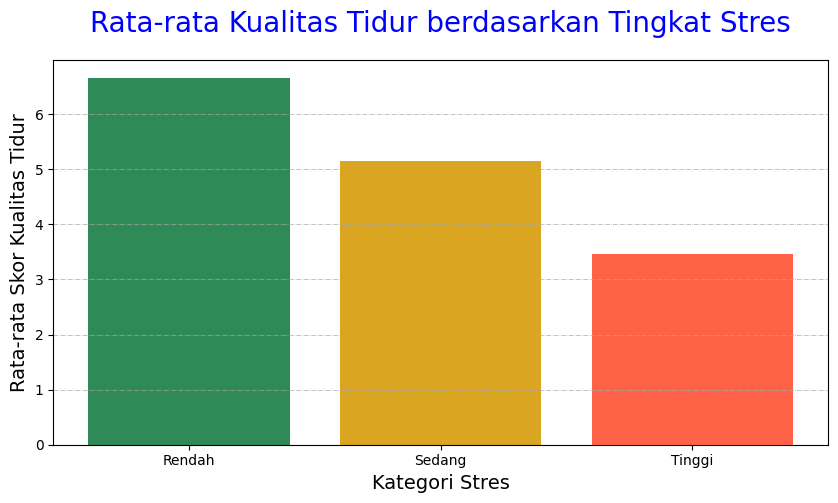

In [108]:
stres = dataset.groupby('kategori_stres')['sleep_quality_score'].mean().loc[['Rendah','Sedang','Tinggi']]
plt.figure(figsize=(10,5))
plt.bar(stres.index, stres.values, color=['seagreen','goldenrod','tomato'])
plt.title('Rata-rata Kualitas Tidur berdasarkan Tingkat Stres', pad=20, fontsize=20, color='blue')
plt.xlabel('Kategori Stres', fontsize=14)
plt.ylabel('Rata-rata Skor Kualitas Tidur', fontsize=14)
plt.grid(axis='y', color='darkgray', linestyle='-.', linewidth=0.5)
plt.show()

**Interpretasi:** stres rendah rata-rata 6,66; sedang 5,15; tinggi 3,46. Stres adalah faktor yang paling terlihat memengaruhi kualitas tidur.

# **VISUALISASI 7 Perbandingan Faktor Gaya Hidup (Subplot)**
> **plt.subplots(1, 3)** membuat satu Figure berisi 3 Axes berdampingan.






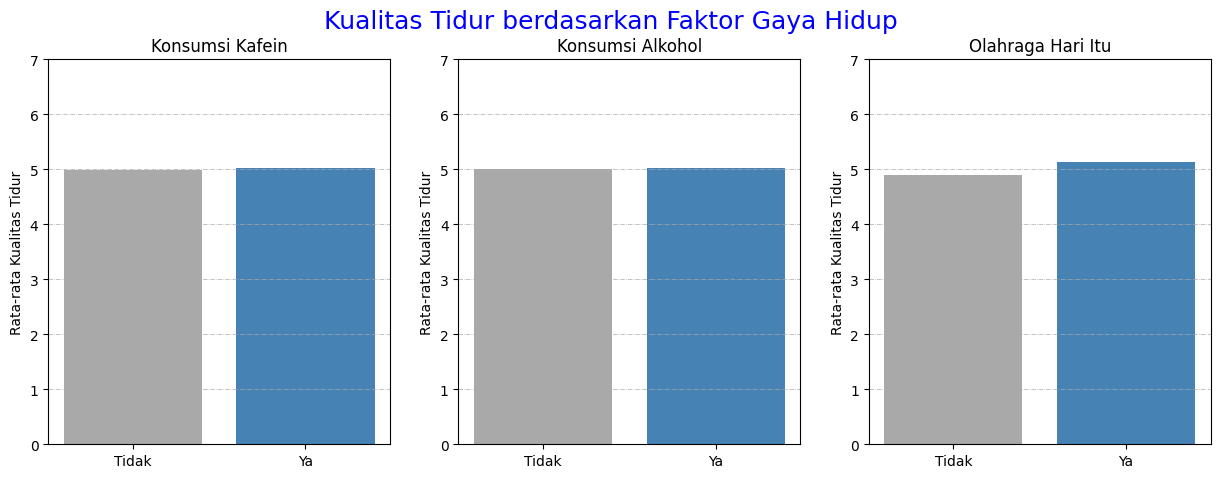

In [109]:
kafein = dataset.groupby('konsumsi_kafein')['sleep_quality_score'].mean()
alkohol = dataset.groupby('konsumsi_alkohol')['sleep_quality_score'].mean()
olahraga = dataset.groupby('exercise_day')['sleep_quality_score'].mean()

fig, axes = plt.subplots(1, 3, figsize=(15,5))
axes[0].bar(['Tidak','Ya'], kafein.values, color=['darkgray','steelblue'])
axes[0].set_title('Konsumsi Kafein')
axes[1].bar(['Tidak','Ya'], alkohol.values, color=['darkgray','steelblue'])
axes[1].set_title('Konsumsi Alkohol')
axes[2].bar(['Tidak','Ya'], olahraga.values, color=['darkgray','steelblue'])
axes[2].set_title('Olahraga Hari Itu')
for ax in axes:
    ax.set_ylim(0, 7)
    ax.set_ylabel('Rata-rata Kualitas Tidur')
    ax.grid(axis='y', color='darkgray', linestyle='-.', linewidth=0.5)
fig.suptitle('Kualitas Tidur berdasarkan Faktor Gaya Hidup', fontsize=18, color='blue')
plt.show()

**Interpretasi:** kafein (4,99 vs 5,03) dan alkohol (5,00 vs 5,02) hampir tidak memengaruhi kualitas tidur. Olahraga sedikit membantu (4,90 vs 5,14).

# **VISUALISASI 8  Kolom Lain: Kategori Kualitas Tidur, Gender, dan Total Tidur Sehari**
> Memakai kolom yang belum dipakai: **kategori_kualitas_tidur,gender, sleep_duration_hrs dan total_tidur_sehari_hrs.**



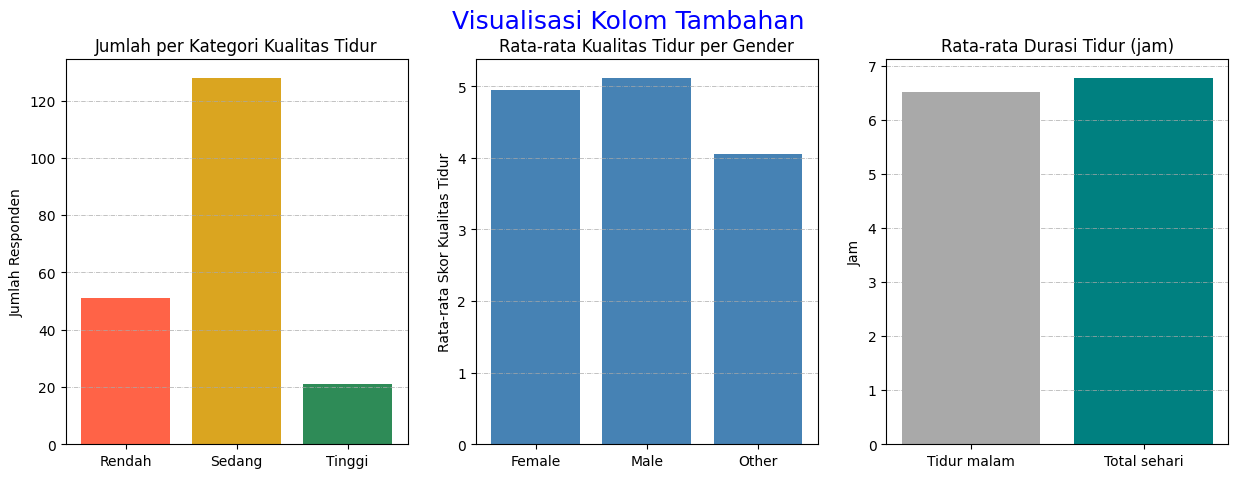

In [110]:
kualitas = dataset['kategori_kualitas_tidur'].value_counts().loc[['Rendah','Sedang','Tinggi']]
gender = dataset.groupby('gender')['sleep_quality_score'].mean()
malam = dataset['sleep_duration_hrs'].mean()
total = dataset['total_tidur_sehari_hrs'].mean()

fig, axes = plt.subplots(1, 3, figsize=(15,5))
axes[0].bar(kualitas.index, kualitas.values, color=['tomato','goldenrod','seagreen'])
axes[0].set_title('Jumlah per Kategori Kualitas Tidur')
axes[0].set_ylabel('Jumlah Responden')
axes[1].bar(gender.index, gender.values, color='steelblue')
axes[1].set_title('Rata-rata Kualitas Tidur per Gender')
axes[1].set_ylabel('Rata-rata Skor Kualitas Tidur')
axes[2].bar(['Tidur malam', 'Total sehari'], [malam, total], color=['darkgray','teal'])
axes[2].set_title('Rata-rata Durasi Tidur (jam)')
axes[2].set_ylabel('Jam')
for ax in axes:
    ax.grid(axis='y', color='darkgray', linestyle='-.', linewidth=0.5)
fig.suptitle('Visualisasi Kolom Tambahan', fontsize=18, color='blue')
plt.show()

**Interpretasi:** kualitas tidur kategori Sedang paling banyak (128), diikuti Rendah (51) dan Tinggi (21). Rata-rata kualitas tidur Female 4,95 dan Male 5,12, sedangkan Other 4,05 (hanya 4 responden, jadi kurang bisa dijadikan acuan). Tidur siang menaikkan rata-rata durasi tidur dari 6,52 jam (malam) menjadi 6,79 jam (total sehari).

## Kesimpulan
1. Data diolah menggunakan Pandas, kemudian diringkas dan ditampilkan dalam bentuk grafik menggunakan Matplotlib, seperti grafik garis, diagram batang, histogram, dan beberapa grafik dalam satu tampilan.
2. Responden berusia 25–34 tahun memiliki kualitas tidur tertinggi, meskipun perbedaannya dengan kelompok usia lain tidak terlalu besar.
3. Sekitar 34% responden tidur kurang dari 6 jam per hari, dengan rata-rata durasi tidur selama 6,52 jam.
4. Durasi tidur yang lebih lama cenderung berkaitan dengan kualitas tidur yang lebih baik, sedangkan tingkat stres yang tinggi cenderung berkaitan dengan kualitas tidur yang lebih rendah.
5. Konsumsi kafein, alkohol, dan aktivitas olahraga menunjukkan hubungan yang relatif kecil dengan kualitas tidur.
6. Seluruh 20 kolom dalam dataset telah dijelaskan pada bagian kamus data, dan sebagian besar telah digunakan dalam analisis serta visualisasi.
7. Melalui visualisasi, pola dan hubungan antarvariabel menjadi lebih mudah dipahami dibandingkan jika hanya melihat data dalam bentuk tabel yang berisi 200 baris.